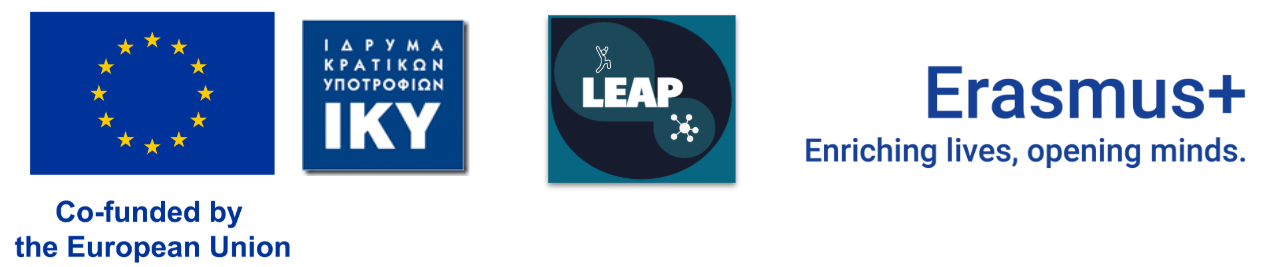

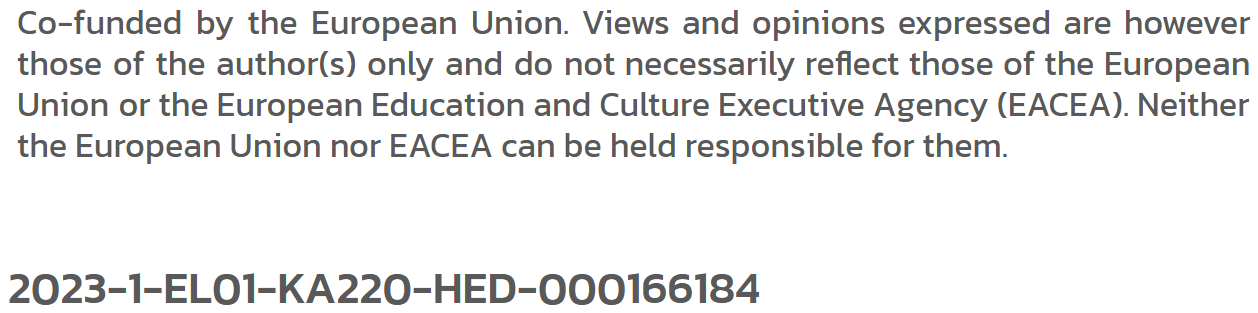

# Final Project, Option 1: Where does your CNN make its mistakes?

Software that reads handwritten numbers, such as postcodes on envelopes or account numbers on paper forms, must be judged not only on how often it is right but on where it goes wrong, because a confident misreading carries a real cost. In this project you build such a model and study the mistakes it makes.

In this project you build a convolutional neural network that recognises handwritten digits, then you study the mistakes it makes.

**Central question:** where does your CNN make its mistakes, and does one change to the model move them?

The data set is MNIST: 70,000 images of handwritten digits, each 28 by 28 pixels in greyscale, labelled 0 to 9. You download it yourself in the next cell.

This project draws on two earlier modules. In Module 5, we built and trained dense neural networks in Keras. In Module 6, we added convolutional layers, used Dropout and EarlyStopping to control overfitting, and read a confusion matrix to see which classes a model mixes up. Here you bring those skills together on a larger, more varied data set.

**How this notebook is organised.** The cells in Part A are already written for you. They handle the import, the download, and the reshaping that turns each flat row of 784 numbers back into a 28 by 28 image. From Part B onward, the cells are yours to complete. Each one carries comments describing what to do, along with a few hints, but not the finished code. Work through them in order.

Training on the full data set may take a few minutes per epoch on a laptop without a graphics card. This is expected.

## Part A. Setup and data

We start with the imports. This cell loads everything the notebook needs, so we run it once at the top.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import keras
from keras import layers

print("Keras Version:", keras.__version__)
print("Backend:", keras.backend.backend())

Keras Version: 3.13.2
Backend: tensorflow


### Loading the data

We download MNIST from OpenML. The call returns the images in `X` as 70,000 rows of 784 numbers, and the labels in `y` as text. We convert the labels to integers so the model can work with them. The download runs once and may take a moment.

In [6]:
X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True)
y = y.astype(int)

print("Images:", X.shape)
print("Labels:", y.shape, "| classes:", np.unique(y))

print("Verification of the greyscale |", f"min value: {X.min()} and max value: {X.max()}")

Images: (70000, 784)
Labels: (70000,) | classes: [0 1 2 3 4 5 6 7 8 9]
Verification of the greyscale | min value: 0 and max value: 255


### Preparing the images

Each row of `X` is one image flattened into a line of 784 numbers. We reshape every row back into a 28 by 28 image with a single greyscale channel, and we scale the pixel values from the range 0 to 255 down to the range 0 to 1, which helps the network train. We then split the data into a training set and a test set, keeping the class balance with `stratify`, as we did in Module 3.

In [10]:
X = X.reshape(-1, 28, 28, 1).astype("float32") / 255.0

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training images:", X_train.shape)
print("Test images:    ", X_test.shape)

print("Pixel values now range from", X_train.min(), "to", X_train.max())

# If training is slow on your machine, you may work with a smaller sample
# while you get everything running, for example:
#   X_train, y_train = X_train[:10000], y_train[:10000]

Training images: (56000, 28, 28, 1)
Test images:     (14000, 28, 28, 1)
Pixel values now range from 0.0 to 1.0


### A first look at the images

Before modelling, we look at a few training images with their labels, to confirm the data loaded correctly.

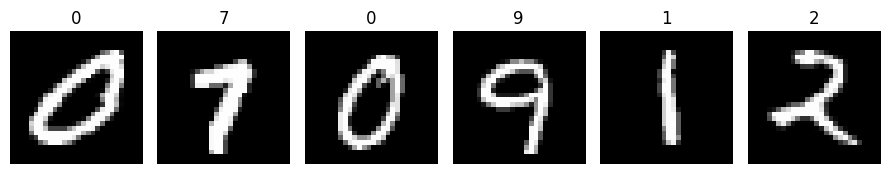

In [11]:
fig, axes = plt.subplots(1, 6, figsize=(9, 2))
for ax, image, label in zip(axes, X_train, y_train):
    ax.imshow(image.reshape(28, 28), cmap="gray")
    ax.set_title(str(label))
    ax.axis("off")
plt.tight_layout()
plt.show()

## Part B. Build and train your network

From here on, the cells are yours to complete.

First, build a convolutional neural network with the Keras Sequential API, the same style you used in Module 6. Recall the shape of one image: 28 by 28, with one channel.

In [14]:
# Build a small convolutional network with the Keras Sequential API.
#
# A sensible starting point has these layers, in order:
#   - an Input layer with the image shape (28, 28, 1)          [given below]
#   - a Conv2D layer      (try 32 filters, a 3 by 3 window, relu activation)
#   - a MaxPooling2D layer (a 2 by 2 window)
#   - a Dropout layer      (0.3 is a reasonable value to start with)
#   - a Flatten layer      (moves from the 2D feature maps to a 1D vector)
#   - a Dense hidden layer (try 64 units, relu)
#   - a Dense output layer (one unit per class, softmax activation)
#
# TODO: complete the layer list below.
# Fix the random seed so that rerunning the notebook gives comparable results.
keras.utils.set_random_seed(42)

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Convolutional and Pooling Layer
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Flatten and Dense Head
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
], name="mnist_digits_cnn")

    # TODO: add the Conv2D and MaxPooling2D layers
    # TODO: add Dropout
    # TODO: add Flatten, then the two Dense layers

model.summary()

Model: "mnist_digits_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       401,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 402,442 (1.54 MB)

 Trainable params: 402,442 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

### Compile the model

Compiling sets the optimiser, the loss function, and the metric to watch during training.

In [15]:
# Compile the model. You need to choose:
#   - an optimiser: "adam" is a solid default
#   - a loss function: the labels are integers 0 to 9, not one-hot vectors,
#     so use the crossentropy loss that works with integer labels
#     (the same one you used in Module 6)
#   - a metric to watch: "accuracy"
#
# TODO: call model.compile(...) with those three arguments.

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)


### Train the model

Train the network, watching how it performs on data it has not learnt from. `EarlyStopping` halts training once the validation loss stops improving, so you do not waste time or overfit.

In [16]:
# Train the model. Use:
#   - validation_split=0.1 so 10% of the training data is held back for checking
#   - an EarlyStopping callback: monitor "val_loss", patience of about 3,
#     and restore_best_weights=True
#   - up to about 15 epochs, and batch_size=128
#
# TODO: create the EarlyStopping callback.
# TODO: call model.fit(...) and store the returned object in `history`.

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)

history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=2,
)


Epoch 1/15
394/394 - 27s - 69ms/step - accuracy: 0.8894 - loss: 0.3759 - val_accuracy: 0.9648 - val_loss: 0.1183
Epoch 2/15
394/394 - 26s - 66ms/step - accuracy: 0.9597 - loss: 0.1356 - val_accuracy: 0.9762 - val_loss: 0.0747
Epoch 3/15
394/394 - 44s - 112ms/step - accuracy: 0.9707 - loss: 0.0980 - val_accuracy: 0.9793 - val_loss: 0.0627
Epoch 4/15
394/394 - 37s - 94ms/step - accuracy: 0.9759 - loss: 0.0813 - val_accuracy: 0.9800 - val_loss: 0.0586
Epoch 5/15
394/394 - 41s - 104ms/step - accuracy: 0.9794 - loss: 0.0668 - val_accuracy: 0.9839 - val_loss: 0.0525
Epoch 6/15
394/394 - 44s - 112ms/step - accuracy: 0.9819 - loss: 0.0587 - val_accuracy: 0.9841 - val_loss: 0.0479
Epoch 7/15
394/394 - 44s - 112ms/step - accuracy: 0.9836 - loss: 0.0516 - val_accuracy: 0.9843 - val_loss: 0.0489
Epoch 8/15
394/394 - 34s - 87ms/step - accuracy: 0.9854 - loss: 0.0462 - val_accuracy: 0.9846 - val_loss: 0.0488
Epoch 9/15
394/394 - 33s - 84ms/step - accuracy: 0.9857 - loss: 0.0437 - val_accuracy: 0.985

### Learning curves

Plot the training and validation loss across the epochs. A validation curve that flattens or turns upward while the training curve keeps falling is a sign of overfitting.

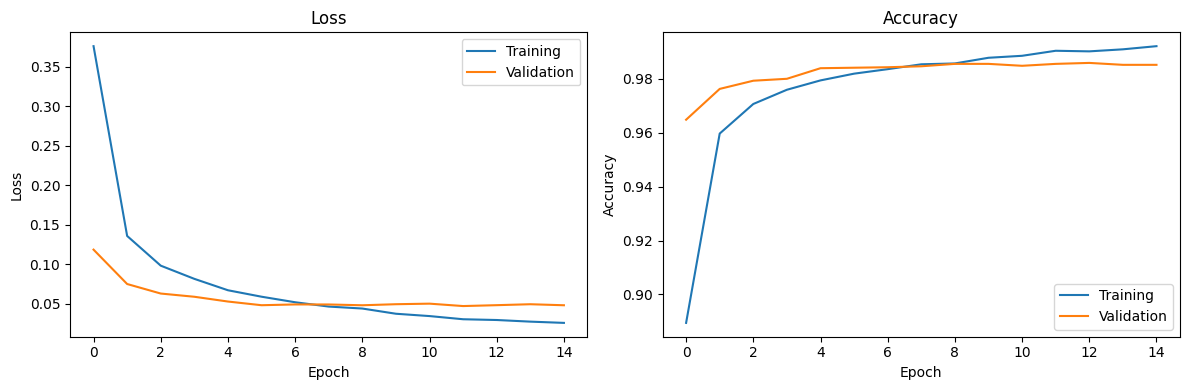

In [17]:
# Plot the training and validation loss from history.history.
# The keys you need are "loss" and "val_loss".
#
# TODO: plot both curves on the same axes, add a legend and axis labels.

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
ax_loss.plot(history.history["loss"], label="Training")
ax_loss.plot(history.history["val_loss"], label="Validation")
ax_loss.set_xlabel("Epoch"); ax_loss.set_ylabel("Loss")
ax_loss.set_title("Loss"); ax_loss.legend()

ax_acc.plot(history.history["accuracy"], label="Training")
ax_acc.plot(history.history["val_accuracy"], label="Validation")
ax_acc.set_xlabel("Epoch"); ax_acc.set_ylabel("Accuracy")
ax_acc.set_title("Accuracy"); ax_acc.legend()

plt.tight_layout()
plt.show()


## Part C. Read the mistakes

Now measure how well the model does on the test set, the images it has never seen. This gives a reliable estimate of how it will perform on new images.

In [18]:
# Evaluate the trained model on the test set, and produce predictions.
#   - model.evaluate(X_test, y_test) returns the loss and the accuracy; store
#     them as test_loss and test_accuracy so you can compare the models later
#   - model.predict(X_test) returns a probability for each of the 10 classes;
#     the predicted digit is the class with the highest probability,
#     which you can get with .argmax(axis=1)
#
# TODO: create test_loss and test_accuracy, then print the test accuracy.
# TODO: build y_pred, the predicted class for each test image.

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test loss: {test_loss:.3f}")

y_pred_probabilities = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probabilities, axis=1)


Test accuracy: 0.986
Test loss: 0.049


### The confusion matrix

The confusion matrix is where you answer the first half of the central question: where the mistakes are. Read it by rows. Each row is a true digit, each column is the digit the model predicted. The diagonal holds the correct predictions; every off-diagonal cell is a mistake, and its position tells you which digit was mistaken for which.

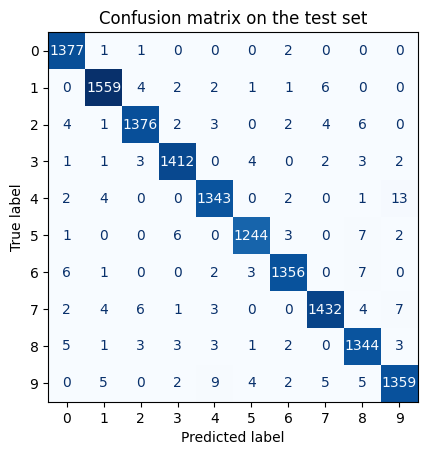

In [19]:
# Build and display the confusion matrix comparing y_test with y_pred.
# Use confusion_matrix(...) to compute it and ConfusionMatrixDisplay(...) to draw it.
#
# TODO: compute the confusion matrix and display it.
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
disp.plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix on the test set")
plt.show()


### What did you find?

Look at the off-diagonal cells with the largest counts. Which pairs of digits does your model confuse most often? Some pairs are visually similar and are commonly mixed up.

**Write two or three sentences here** naming the two most common confusion pairs, recording the count for each one, and suggesting why those particular digits might be hard to tell apart. For example, if row 4 and column 9 contains 18, the model predicted 9 for 18 images that were actually 4.


---


For the error analysis, as it seems from the confusion matrix above, the model has trouble to distinct 4 and 9 pair digits. There was 13 image cases from the test set, depicting number 4, that the model classified as 9, 9 image cases of the digit 9, that the model wrongly classified as 4. So, clearly the model has trouble to classify correctly this pair. This difficulty, maybe is happening, because in both 4 and 9 digits, there are higher values in the normalized greyscale in the pixels in the right part of the image with a somewhat curvature in the pixels in left. Also, there were 7 instance 7 classified as 9, and 5 or 6 classified as 8.

The pairs that the model had trouble to distinct: <br>
4 <-> 9 <br>
7 --> 9 <br>
5 or 6 --> 8


## Part D. One change

Now answer the second half of the central question: does one change to the model move the mistakes?

Choose **one** change from the two below. Do not make both at once, or you will not know which one caused any difference you see.

- **Option A: a deeper network.** Before the Flatten layer, add `Conv2D(64, (3, 3), activation="relu")` followed by `MaxPooling2D((2, 2))`. This lets the network learn more detailed patterns.
- **Option B: stronger regularisation.** Raise the Dropout rate from 0.3 to 0.5. This makes the network rely less on any single feature.

**Before you run anything, write down your prediction:** will your chosen change raise the test accuracy, and will it reduce the confusion between the pairs you found in Part C? Note it here.

Neural-network training contains some randomness. A very small difference in accuracy does not necessarily show that one model is genuinely better. Look at the size of the difference and at the specific mistakes, not only at which accuracy is larger.



---


**Notes:**

I chose Option A: To construct a deeper network, by adding before the Flatten layer the propriate convolutional and pooling layers, with all other parameters unchanged so we can compare the two models. By intuition, before running the code I was expecting that a deeper architecture of a model, will show an increase in the test accuracy of the model, and reduce the wrong instances we pointed out from the confusion matrix. But after running the code, that wasn't even the case, the test accuracy was worse than our first model and had more trouble distinct the images generally. Although, I was able to spot, there was some sensitivity to the splits, I run the model for 2nd time and it showed comparable, but better accuracy and better overall distinction of the images. The epochs, test accuracy and confusion matrix are added in the repository in the added images file.

In [20]:
# Build a second model that applies your ONE chosen change.
# Start from your Part B model and change only what Option A or Option B asks for.
#
# Use the same seed as before to make the comparison more reproducible.
keras.utils.set_random_seed(42)

model2 = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # First Convolutional and Pooling Layer
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Option A: A deeper network
    # Second Convolutional and Pooling Layer
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Flatten and Dense Head
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
], name="mnist_digits_cnn2")

model2.summary()

# TODO: define model2 with your single change, then call model2.summary().


Model: "mnist_digits_cnn2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,234 (860.29 KB)

 Trainable params: 220,234 (860.29 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Compile and train model2 exactly as you trained the first model,
# so the comparison is fair (same optimiser, loss, metric, callback, and settings).
#
# TODO: compile model2, then fit it and store the result in history2.

model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history2 = model2.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=2,
)


Epoch 1/15
394/394 - 65s - 166ms/step - accuracy: 0.9054 - loss: 0.3107 - val_accuracy: 0.9752 - val_loss: 0.0788
Epoch 2/15
394/394 - 78s - 198ms/step - accuracy: 0.9718 - loss: 0.0945 - val_accuracy: 0.9816 - val_loss: 0.0578
Epoch 3/15
394/394 - 81s - 205ms/step - accuracy: 0.9794 - loss: 0.0657 - val_accuracy: 0.9845 - val_loss: 0.0478


Test accuracy of model 1: 0.986 and model 2: 0.976
Test loss of model 1: 0.079 and model 2: 0.079


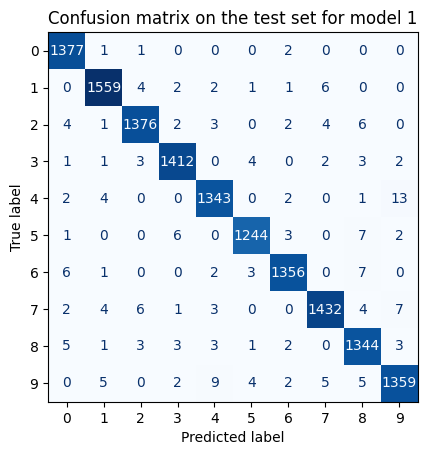

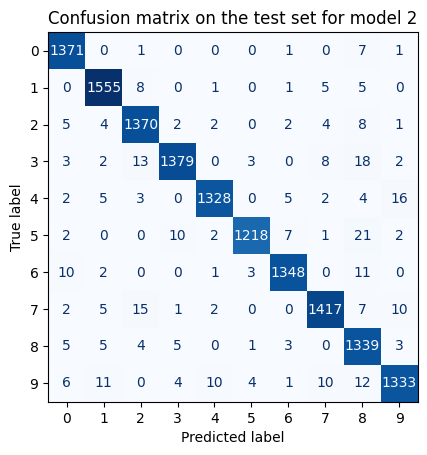

In [22]:
# Compare the two models.
#   - store the results as test_loss2 and test_accuracy2
#   - print test_accuracy2 next to the first model's test_accuracy
#   - build y_pred2 and draw the new confusion matrix
#   - compare the counts for the two confusion pairs you identified in Part C
#
# TODO: evaluate model2, then compute and display its confusion matrix.

test_loss2, test_accuracy2 = model2.evaluate(X_test, y_test, verbose=0)

print(f"Test accuracy of model 1: {test_accuracy:.3f} and model 2: {test_accuracy2:.3f}")
print(f"Test loss of model 1: {test_loss2:.3f} and model 2: {test_loss2:.3f}")

y_pred_probabilities2 = model2.predict(X_test, verbose=0)
y_pred2 = np.argmax(y_pred_probabilities2, axis=1)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
disp.plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix on the test set for model 1")
plt.show()

cm2 = confusion_matrix(y_test, y_pred2)

disp = ConfusionMatrixDisplay(confusion_matrix=cm2, display_labels=range(10))
disp.plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix on the test set for model 2")
plt.show()


### Ethical considerations

A digit reader does not perform equally well for everyone. Handwriting varies by age, country, and schooling, and a model trained mostly on one style may read another less reliably.
**Write two or three sentences here** on the risks of putting this model into a real reading pipeline. Consider whose handwriting might be under-represented in the training data, and what the consequence of a confident but wrong reading would be in the setting above.



---

This project is a first attempt to classify correctly number digits and it is trained based on the MNIST784 dataset. Without knowing a lot about the deep details of the dataset it could have a bias in the images used. We have to consider things that did images are written from well educated people, healthy people that don't have Parkinson's Disease or other conditions that could influence their handwriting, elder people also could have some difficulties in their handwriting and generally there is a wide variety of how the digits are written by people. For example, for the digit 7, some people also use a horizontal line in the middle that could trick the model. For a high-stakes task, such as in this scenario that this software could be potentially used by a postal sorting centre or a bank, the mistakes are not passed lightly. So, this isn't the end for the goal classifying correctly the number digits, but it seems it is more than a simple start.


## Wrapping up

Bring your findings together. **Write a short paragraph** that answers the central question directly:

- Where did your first model make most of its mistakes?
- Did your prediction in Part D turn out to be correct?
- For each of the two confusion pairs you identified, what was the count before and after the change?
- Did your one change move the mistakes, and is the difference large enough to be meaningful?

**What to hand in:** this completed notebook, with both confusion matrices visible in the output, and your written answers in the three markdown cells above (Part C, Part D, and this one).



---

- The first model had most trouble distinct 4 and 9 digit pair, while there were instances, that 7 classified wrongly as digit 9, and 5 and 6 classified wrongly as digit 8
- My prediction for the second deeper network, was incorrect. A more complicated architecture of a model doesn't necessarily mean better results, here the results were comparable generally, test accuracy of model 1 and 2 were 0.986 and 0.976 accordingly. Also, we note there is a limitation in this project, as we found there could be a potential sensitivity in the splits of the training - test data. We could address this in the future with employing StratifiedKFold to have a more general picture of the models.
- The 2nd model had more generally trouble identifying the right digits overall at the first run, the results were better than the first model in the second run of the 2nd model. For the digit pair 4 <--> 9, first model had 13 images, that depicted digit 4 and model classified it as 9 and 9 images that depicted digit 9, that model identified it as 4, also there were 7 instances images that depicted 5 and 6 each, that model identified them as 8. In the 2nd model for these pairs, the model achieved the following: <br> <br>
4 --> 9 Model 1: 13 images --> Model 2 (first run): 16 --> Model 2 (second run): 11 <br>
9 --> 4 Model 1: 9 images --> Model 2 (first run): 10 --> Model 2 (second run): 11 <br>
5 --> 8 Model 1: 7 images --> Model 2 (first run): 21 --> Model 2 (second run): 3 <br>
6 --> 8 Model 1: 7 images --> Model 2 (first run): 11 --> Model 2 (second run): 3 <br> <br>
-Changing the first model with deeper network, didn't move the mistakes, the models seems it has trouble to distinct 8 and 9, in the first run of second model thought, it showed more wrong instances for the 8 digits, but in the second run of it, it showed better but comparable performance to first model, but the most mistakes remained in the 4 <--> 9 pair as you can see in the screenshot image, in the added images file in the github repository.
